Data shape: (2000, 2)
Boundary pixels: 1000  Non-boundary pixels: 1000
Shape after Kernel PCA: (2000, 2)
Original Centre (Non-Boundary): [ 0.0251 -0.0206]
Original Centre (Boundary): [-0.0251  0.0206]
Kernel PCA Centre (Non-Boundary): [-0.1031  0.0122]
Kernel PCA Centre (Boundary): [ 0.1031 -0.0122]


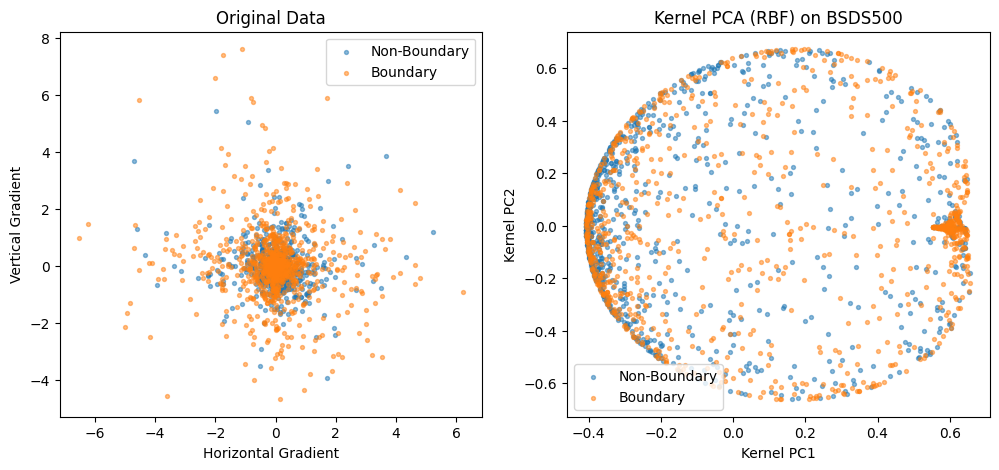

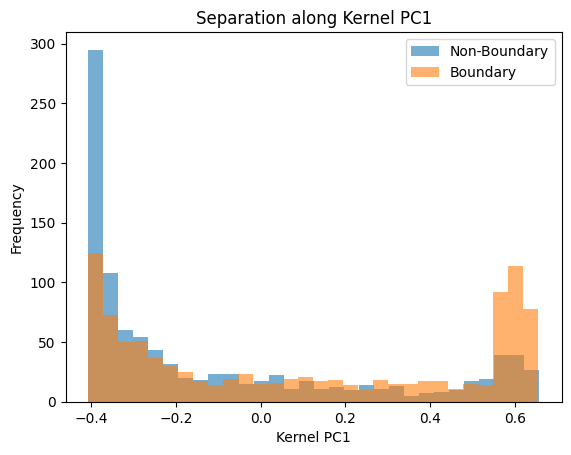

In [1]:
import os
import glob
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from scipy.io import loadmat
from scipy.ndimage import sobel
from sklearn.decomposition import KernelPCA
from sklearn.preprocessing import StandardScaler

path = "Datasets/BSDS500"

images = sorted(glob.glob(path + "/**/*.jpg", recursive=True))
gtmap = {}
for m in glob.glob(path + "/**/*.mat", recursive=True):
    gtmap[os.path.basename(m)[:-4]] = m


def get_labels(name, shape):
    d = loadmat(gtmap[name])["groundTruth"]
    b = np.zeros(shape)
    for i in range(d.shape[1]):
        b = b + d[0, i]["Boundaries"][0, 0]
    return (b > 0).astype(int).reshape(-1)


np.random.seed(1)
X = []
y = []
for f in images[:20]:
    name = os.path.basename(f)[:-4]
    g = np.array(Image.open(f).convert("L"), dtype=float) / 255.0
    gx = sobel(g, axis=1).reshape(-1)
    gy = sobel(g, axis=0).reshape(-1)
    L = get_labels(name, g.shape)
    pos = np.random.choice(np.where(L == 1)[0], 50, replace=False)
    neg = np.random.choice(np.where(L == 0)[0], 50, replace=False)
    idx = np.concatenate([pos, neg])
    X.append(np.column_stack([gx[idx], gy[idx]]))
    y.append(L[idx])

X = np.vstack(X)
y = np.concatenate(y)
X = StandardScaler().fit_transform(X)

print("Data shape:", X.shape)
print("Boundary pixels:", int(y.sum()), " Non-boundary pixels:", int(len(y) - y.sum()))

kpca = KernelPCA(n_components=2, kernel="rbf", gamma=1)
Xk = kpca.fit_transform(X)

print("Shape after Kernel PCA:", Xk.shape)
print("Original Centre (Non-Boundary):", np.round(X[y == 0].mean(axis=0), 4))
print("Original Centre (Boundary):", np.round(X[y == 1].mean(axis=0), 4))
print("Kernel PCA Centre (Non-Boundary):", np.round(Xk[y == 0].mean(axis=0), 4))
print("Kernel PCA Centre (Boundary):", np.round(Xk[y == 1].mean(axis=0), 4))

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].scatter(X[y == 0][:, 0], X[y == 0][:, 1], s=8, alpha=0.5, label="Non-Boundary")
ax[0].scatter(X[y == 1][:, 0], X[y == 1][:, 1], s=8, alpha=0.5, label="Boundary")
ax[0].set_xlabel("Horizontal Gradient")
ax[0].set_ylabel("Vertical Gradient")
ax[0].set_title("Original Data")
ax[0].legend()
ax[1].scatter(Xk[y == 0][:, 0], Xk[y == 0][:, 1], s=8, alpha=0.5, label="Non-Boundary")
ax[1].scatter(Xk[y == 1][:, 0], Xk[y == 1][:, 1], s=8, alpha=0.5, label="Boundary")
ax[1].set_xlabel("Kernel PC1")
ax[1].set_ylabel("Kernel PC2")
ax[1].set_title("Kernel PCA (RBF) on BSDS500")
ax[1].legend()
plt.show()

plt.hist(Xk[y == 0][:, 0], bins=30, alpha=0.6, label="Non-Boundary")
plt.hist(Xk[y == 1][:, 0], bins=30, alpha=0.6, label="Boundary")
plt.xlabel("Kernel PC1")
plt.ylabel("Frequency")
plt.title("Separation along Kernel PC1")
plt.legend()
plt.show()
